<a href="https://colab.research.google.com/github/emerson-marreiros/Quantum-Kernels/blob/main/Quantum_Kernels_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Quantum Kernels**

Vamos compreender como circuitos quânticos podem transformar dados clássicos em representações de alta dimensionalidade e como essa representação pode ser utilizada por algoritmos de aprendizagem de máquina, especialmente o QSVM (Quantum Support Vector Machine).

Vamos conectar teoria de kernels ou núcleo(s) (é a parte central e mais importante de um sistemas operacional. Ele atua como uma ponte fundamental entre o hardware do computador ("*processador, memória RAM, palcas, discos*") e os software ("*aplicativos, navegadores e o próprio usuário*") sem kernel, os programas instalados no computador ou celular não conseguiriam se comunicar com as peças físicas da máquina), fidelidade quântica, feature maps parametrizados, alinhamento de kernels (QKA), visualização geométrica e experimentos computacionais reproduzíveis.



**Por que estudar kernels quânticos?**

Em aprendizagem de máquina, muitas tarefas tornam-se mais simples quando os dados são representados em um espaço onde as classes ficam separáveis. Um kernel permite trabalhar com produtos internos nesse espaço sem precisar construir explicitamente todos os vetores transformados.

A proposta quântica consiste em utilizar um circuito para realizar uma transformação de características:

$
x\longmapsto |\phi(x)\rangle=U_\phi(x)|0\rangle^{\otimes n}.
$

Em seguida, comparamos os estados produzidos para duas amostras. A fidelidade entre eles define um kernel que pode alimentar um classificador clássico, como uma SVM.

**Teoria matemática dos kernels quânticos**

**Kernel clássico**

Um kernel clássico mede a similaridade entre duas amostras \(x\) e \(x'\) por meio de uma representação $\varphi(x)$:
$
K(x,x')=\langle\varphi(x),\varphi(x')\rangle.
$

A função $\varphi$ pode levar os dados para um espaço de dimensão maior. O kernel trick permite calcular produtos internos nesse espaço sem precisar construir explicitamente cada vetor transformado.

Um exemplo é o kernel RBF:

$
K_{\mathrm{RBF}}(x,x')
=\exp\left(-\gamma\|x-x'\|^2\right).
$

Ele atribui valores próximos de 1 a amostras semelhantes e valores menores a amostras mais distantes, conforme o parâmetro \(\gamma\).

Kernel quântico baseado em fidelidade
Um circuito de codificação transforma uma entrada clássica em um estado quântico:
$
|\phi(x)\rangle=U_\phi(x)|0\rangle^{\otimes n}.
$

O kernel quântico de fidelidade é definido como

$
\boxed{
K_q(x,x')=
|\langle\phi(x)|\phi(x')\rangle|^2
}
$

A expressão representa a fidelidade entre dois estados puros. Seus valores estão entre zero e um:
- $K_q\approx1$: estados muito semelhantes.
- $K_q\approx0$: estados quase ortogonais.
- $K_q=1$: estados fisicamente equivalentes até uma fase global.

A fidelidade é uma medida de similaridade entre estados, não uma distância métrica por si só.

Por que aparece a dimensão $(2^n)$?

Cada qubit possui um espaço de estados de dimensão 2.

Para $n$ qubits, o espaço conjunto tem dimensão
$
\dim(\mathcal H)=2^n.
$

Isso não significa que toda codificação quântica produza uma vantagem.

A dimensão exponencial do espaço de estados não garante que um classificador consiga explorar essa estrutura eficientemente, nem que o cálculo do kernel seja barato.

O papel do emaranhamento
Considere um feature map com portas de rotação e CNOT:
$
U_\phi(x)=
\operatorname{CNOT}
\left[R_Y(x_0)\otimes R_Y(x_1)\right].
$

As rotações codificam características nos estados dos qubits. A CNOT pode introduzir emaranhamento, dependendo do estado de entrada.

O emaranhamento pode enriquecer a representação dos dados, mas não é obrigatório que ele melhore a classificação.

Sua utilidade depende do problema e da arquitetura.

**Fidelidade e circuito de avaliação**

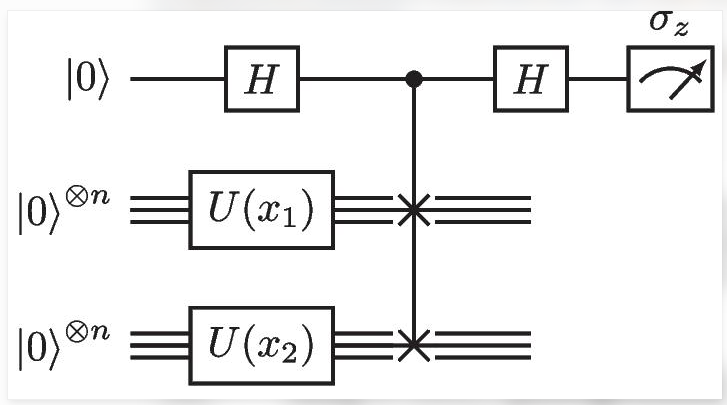

**Figura 1** — Estratégia compute–uncompute. O circuito prepara o estado associado a uma amostra, aplica a transformação inversa correspondente à outra amostra e mede a probabilidade de retornar ao estado de referência.

Para estados preparados por $\(U_\phi(x)\)$ e $U_\phi(x')$, o circuito calcula a probabilidade
$
P(0^n)=
\left|
\langle0^n|
U_\phi^\dagger(x')U_\phi(x)
|0^n\rangle
\right|^2.
$

Essa probabilidade é justamente $K_q(x,x')$.
Outra abordagem é o teste SWAP, que utiliza um qubit auxiliar e portas SWAP controladas para estimar a sobreposição entre estados. Para estados puros, a probabilidade de medir o auxiliar em zero satisfaz
$
P(0)=\frac{1+|\langle\phi(x)|\phi(x')\rangle|^2}{2}.
$

Portanto,
$
K_q(x,x')=2P(0)-1.
$

Na prática, o FidelityQuantumKernel do Qiskit utiliza uma rotina de fidelidade baseada em compute–uncompute por padrão, não necessariamente um teste SWAP.

**Kernel Alignment e QKA**

Uma matriz de kernel pode ser matematicamente válida e, mesmo assim, não separar bem as classes de interesse. O alinhamento com os rótulos ajuda a avaliar se a similaridade definida pelo kernel corresponde à estrutura da tarefa.
Para um conjunto com $N$ amostras e rótulos binários $y_i\in\{-1,+1\}$, definimos a matriz-alvo
$
T=yy^\top.
$

Uma medida de alinhamento normalizado é
$
A(K,T)=
\frac{\langle K,T\rangle_F}
{\|K\|_F\|T\|_F},
$

em que $\langle\cdot,\cdot\rangle_F$ representa o produto interno de Frobenius.

O Quantum Kernel Alignment (QKA) ajusta parâmetros $\theta$ de um feature map para melhorar a compatibilidade do kernel com os rótulos:
$
\theta^*=\arg\max_\theta A(K_\theta,T).
$

Essa expressão é uma formulação didática de alinhamento normalizado. Implementações práticas podem usar perdas diferentes, regularização, kernels centralizados e procedimentos próprios de otimização.

A ideia central é aprender uma representação mais adequada à tarefa, em vez de escolher um circuito inteiramente fixo. O Qiskit Machine Learning disponibiliza TrainableFidelityQuantumKernel e QuantumKernelTrainer para esse tipo de treinamento.



**Ambiente computacional: Qiskit**

Para executar a aula no Google Colab, utilize uma célula de instalação:


In [1]:
%pip install "qiskit>=1.0,<2.0" "qiskit-machine-learning>=0.8,<0.9" "scikit-learn>=1.4" matplotlib seaborn scipy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.7/6.7 MB 53.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 231.9/231.9 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 18.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 61.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.6/49.6 MB 16.0 MB/s eta 0:00:00
  Attempting uninstall: scipy
    Found existing installation: scipy 1.16.3
    Uninstalling scipy-1.16.3:
      Successfully uninstalled scipy-1.16.3


**Experimento 1 — Dataset ad hoc e matriz de kernel $10\times10$**

O dataset ad hoc foi desenvolvido para estudar classificadores quânticos baseados em feature maps, incluindo a codificação ZZ de Havlíček. É uma escolha útil porque permite observar o comportamento de um kernel projetado para a tarefa, sem depender de dados externos.

**Código 1 — Preparação, fidelidade e visualização**


Treino: (10, 2)
Teste: (10, 2)
Classes: [0 1]
Dimensão da matriz: (10, 10)
Mínimo: 0.0029296875000001943
Máximo: 1.0000000000000016
Simétrica: True


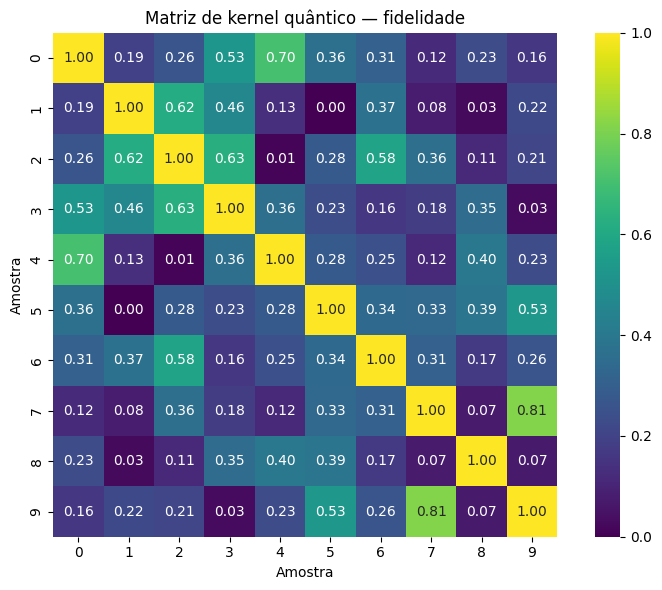

In [2]:

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from qiskit.circuit.library import zz_feature_map
from qiskit.primitives import StatevectorSampler
from qiskit_machine_learning.datasets import ad_hoc_data
from qiskit_machine_learning.state_fidelities import ComputeUncompute
from qiskit_machine_learning.kernels import FidelityQuantumKernel

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.preprocessing import LabelEncoder

SEED = 42
np.random.seed(SEED)

# Dataset de Havlicek: 2 features e duas classes.
X_train, y_train, X_test, y_test = ad_hoc_data(
    training_size=5,
    test_size=5,
    n=2,
    gap=0.3,
    one_hot=False
)

X_train = np.asarray(X_train, dtype=float)
X_test = np.asarray(X_test, dtype=float)
y_train = np.asarray(y_train).ravel()
y_test = np.asarray(y_test).ravel()

print("Treino:", X_train.shape)
print("Teste:", X_test.shape)
print("Classes:", np.unique(y_train))

# Feature map quântico.
feature_map = zz_feature_map(
    feature_dimension=2,
    reps=2,
    entanglement="linear"
)

# Primitiva de amostragem local e cálculo de fidelidade.
sampler = StatevectorSampler(seed=SEED)
fidelity = ComputeUncompute(sampler=sampler)

quantum_kernel = FidelityQuantumKernel(
    feature_map=feature_map,
    fidelity=fidelity
)

# Matriz 10 x 10 de fidelidades.
K_train = quantum_kernel.evaluate(X_train)

print("Dimensão da matriz:", K_train.shape)
print("Mínimo:", K_train.min())
print("Máximo:", K_train.max())
print("Simétrica:", np.allclose(K_train, K_train.T, atol=1e-7))

plt.figure(figsize=(8, 6))
sns.heatmap(
    K_train,
    cmap="viridis",
    vmin=0,
    vmax=1,
    annot=True,
    fmt=".2f",
    square=True
)
plt.title("Matriz de kernel quântico — fidelidade")
plt.xlabel("Amostra")
plt.ylabel("Amostra")
plt.tight_layout()
plt.show()


O gerador retorna amostras de treino e teste; a matriz exibida utiliza as dez amostras de treino, correspondentes a cinco exemplos por classe.

O simulador de estados fornece uma avaliação local idealizada, sem ruído físico.

Entendendo o heatmap
- A diagonal principal deve apresentar valores iguais ou muito próximos de 1.
- Regiões de valores altos indicam pares de estados com grande fidelidade.
- Valores baixos indicam estados com pouca sobreposição.
- Se houver blocos associados às classes, o kernel pode estar capturando uma estrutura útil para a classificação.

A existência de blocos visuais não garante, por si só, uma boa generalização.
É necessário avaliar o conjunto de teste.

**Experimento 2 — QSVM versus SVM com kernel RBF**

Neste experimento, utilizaremos o kernel quântico como função de similaridade de uma SVM convencional. A otimização dos coeficientes da SVM é clássica; a parte quântica está no cálculo da matriz de kernel.

**Código 2 — Treinamento e comparação**

Acurácia QSVM: 0.900
Acurácia RBF:  0.700

Relatório QSVM:
              precision    recall  f1-score   support

           0       1.00      0.80      0.89         5
           1       0.83      1.00      0.91         5

    accuracy                           0.90        10
   macro avg       0.92      0.90      0.90        10
weighted avg       0.92      0.90      0.90        10


Relatório RBF:
              precision    recall  f1-score   support

           0       0.67      0.80      0.73         5
           1       0.75      0.60      0.67         5

    accuracy                           0.70        10
   macro avg       0.71      0.70      0.70        10
weighted avg       0.71      0.70      0.70        10



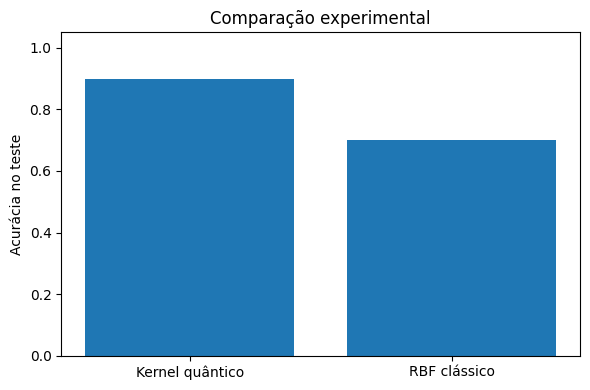

In [3]:

# SVM com kernel quântico.
qsvm = SVC(kernel=quantum_kernel.evaluate, C=1.0)
qsvm.fit(X_train, y_train)
pred_q = qsvm.predict(X_test)

acc_q = accuracy_score(y_test, pred_q)

# SVM clássico com kernel RBF.
classical_svm = SVC(kernel="rbf", C=1.0, gamma="scale")
classical_svm.fit(X_train, y_train)
pred_rbf = classical_svm.predict(X_test)

acc_rbf = accuracy_score(y_test, pred_rbf)

print(f"Acurácia QSVM: {acc_q:.3f}")
print(f"Acurácia RBF:  {acc_rbf:.3f}")

print("\nRelatório QSVM:")
print(classification_report(y_test, pred_q, zero_division=0))

print("\nRelatório RBF:")
print(classification_report(y_test, pred_rbf, zero_division=0))

plt.figure(figsize=(6, 4))
plt.bar(
    ["Kernel quântico", "RBF clássico"],
    [acc_q, acc_rbf]
)
plt.ylim(0, 1.05)
plt.ylabel("Acurácia no teste")
plt.title("Comparação experimental")
plt.tight_layout()
plt.show()


Sobre a alegação “kernel quântico 100% versus RBF 70%”

Esses números podem ocorrer em determinados experimentos, mas não são resultados garantidos pelo dataset ad hoc, nem devem ser apresentados como uma conclusão universal.

O desempenho depende da amostragem, do tamanho do conjunto, do parâmetro gap, do feature map, dos hiperparâmetros e da divisão treino/teste. Em conjuntos muito pequenos, a acurácia varia bastante.

Para uma comparação científica rigorosa:
1. Utilize as mesmas amostras e os mesmos rótulos nos dois métodos.
2. Ajuste os hiperparâmetros apenas na validação.
3. Repita o experimento com várias sementes.
4. Compare médias e desvios-padrão.
5. Registre o custo de construção da matriz, o número de avaliações de circuito e os recursos computacionais.
Uma acurácia de 100% em um teste pequeno não comprova vantagem quântica.

**Experimento 3 — QKA: alinhamento antes e depois do treinamento**

Agora vamos construir um feature map próprio com dois parâmetros de entrada e um parâmetro treinável $\theta$. Utilizaremos o kernel de fidelidade treinável do Qiskit e otimizaremos o alinhamento normalizado com os rótulos por meio do SciPy.

Esta implementação demonstra o princípio do QKA diretamente, sem depender de uma configuração específica do QuantumKernelTrainer. Para experimentos de pesquisa, o treinador oficial do Qiskit também é uma alternativa.


**Código 3 — Feature map parametrizado**

In [6]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit_machine_learning.kernels import TrainableFidelityQuantumKernel
from scipy.optimize import minimize

# Usamos um nome que não conflite com as variáveis internas do Qiskit (evitar 'x' ou 'y')
x = ParameterVector("data_x", 2)
theta = ParameterVector("theta", 1)

fm_trainable = QuantumCircuit(2)
fm_trainable.h(0)
fm_trainable.h(1)

fm_trainable.rz(x[0], 0)
fm_trainable.ry(x[1], 1)

fm_trainable.cx(0, 1)
fm_trainable.rz(theta[0], 1)
fm_trainable.cx(0, 1)

fm_trainable.rz(x[0] * x[1], 0)
fm_trainable.ry(x[0] + x[1], 1)

trainable_kernel = TrainableFidelityQuantumKernel(
    feature_map=fm_trainable,
    fidelity=fidelity,
    training_parameters=list(theta)
)

print(fm_trainable.draw(output="text"))
print("Parâmetros treináveis:",
      trainable_kernel.num_training_parameters)

     ┌───┐┌───────────────┐                          »
q_0: ┤ H ├┤ Rz(data_x[0]) ├──■────────────────────■──»
     ├───┤├───────────────┤┌─┴─┐┌──────────────┐┌─┴─┐»
q_1: ┤ H ├┤ Ry(data_x[1]) ├┤ X ├┤ Rz(theta[0]) ├┤ X ├»
     └───┘└───────────────┘└───┘└──────────────┘└───┘»
«      ┌─────────────────────────┐ 
«q_0: ─┤ Rz(data_x[0]*data_x[1]) ├─
«     ┌┴─────────────────────────┴┐
«q_1: ┤ Ry(data_x[0] + data_x[1]) ├
«     └───────────────────────────┘
Parâmetros treináveis: 1


O circuito utiliza rotações locais e uma sequência de CNOTs. O parâmetro \(\theta\) altera a transformação quântica e, consequentemente, a geometria das similaridades entre as amostras.


**Código 4 — Alinhamento e otimização**

Para evitar vazamento de informação, a otimização utiliza apenas os dados de treino. Os rótulos são convertidos para \(-1,+1\), formando a matriz-alvo.

Theta inicial: 0.2000
Theta otimizado: 0.1944
Alinhamento antes: 0.0545
Alinhamento depois: 0.0547
Otimização convergiu: True


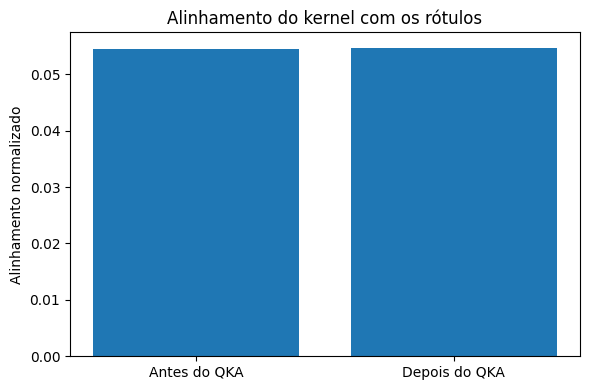

In [7]:
# Rótulos binários para construir T = y y^T.
encoder = LabelEncoder()
y_binary = encoder.fit_transform(y_train)

if len(np.unique(y_binary)) != 2:
    raise ValueError("Este exemplo de QKA requer duas classes.")

y_pm = 2 * y_binary - 1
T = np.outer(y_pm, y_pm).astype(float)

def alignment(K, T):
    """Alinhamento normalizado de Frobenius."""
    numerator = np.sum(K * T)
    denominator = np.linalg.norm(K) * np.linalg.norm(T)
    return float(numerator / denominator) if denominator else 0.0

def kernel_at(theta_value):
    trainable_kernel.assign_training_parameters(
        np.asarray([theta_value], dtype=float)
    )
    return trainable_kernel.evaluate(X_train)

# Alinhamento inicial.
theta_initial = 0.2
K_before = kernel_at(theta_initial)
alignment_before = alignment(K_before, T)

# Maximizar alinhamento equivale a minimizar seu negativo.
def objective(params):
    K = kernel_at(params[0])
    return -alignment(K, T)

result = minimize(
    objective,
    x0=np.array([theta_initial]),
    method="Nelder-Mead",
    options={"maxiter": 40, "xatol": 1e-3}
)

theta_opt = float(result.x[0])
K_after = kernel_at(theta_opt)
alignment_after = alignment(K_after, T)

print(f"Theta inicial: {theta_initial:.4f}")
print(f"Theta otimizado: {theta_opt:.4f}")
print(f"Alinhamento antes: {alignment_before:.4f}")
print(f"Alinhamento depois: {alignment_after:.4f}")
print("Otimização convergiu:", result.success)

plt.figure(figsize=(6, 4))
plt.bar(
    ["Antes do QKA", "Depois do QKA"],
    [alignment_before, alignment_after]
)
plt.ylabel("Alinhamento normalizado")
plt.title("Alinhamento do kernel com os rótulos")
plt.tight_layout()
plt.show()

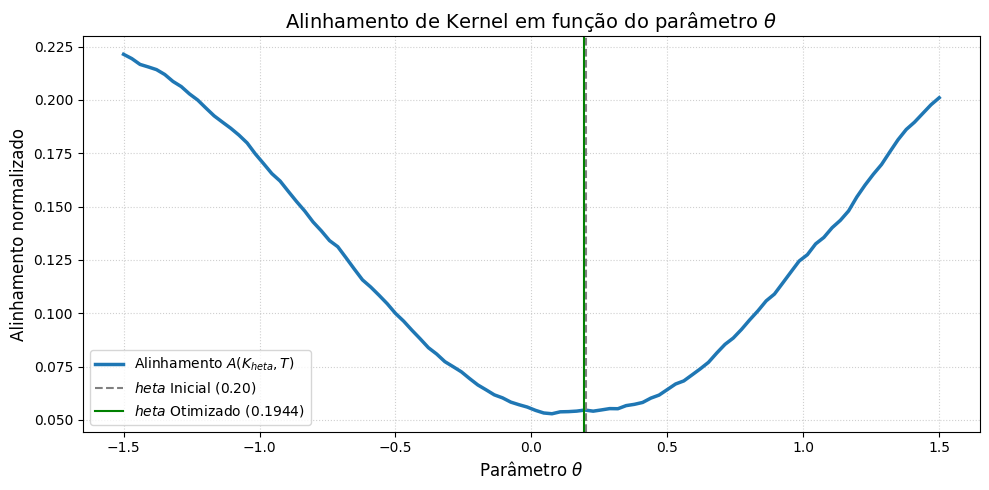

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Gerando 100 pontos de theta no intervalo [-1.5, 1.5]
theta_vals = np.linspace(-1.5, 1.5, 100)
alignments = []

# Calculando o alinhamento para cada theta
for val in theta_vals:
    K_val = kernel_at(val)
    alignments.append(alignment(K_val, T))

# Plotando o gráfico de linha do alinhamento
plt.figure(figsize=(10, 5))
plt.plot(theta_vals, alignments, label="Alinhamento $A(K_{\theta}, T)$", color="#1f77b4", linewidth=2.5)
plt.axvline(theta_initial, color="gray", linestyle="--", label=f"$\theta$ Inicial ({theta_initial:.2f})")
plt.axvline(theta_opt, color="green", linestyle="-", label=f"$\theta$ Otimizado ({theta_opt:.4f})")

plt.title("Alinhamento de Kernel em função do parâmetro $\\theta$", fontsize=14)
plt.xlabel("Parâmetro $\\theta$", fontsize=12)
plt.ylabel("Alinhamento normalizado", fontsize=12)
plt.grid(True, linestyle=":", alpha=0.6)
plt.legend(loc="best")
plt.tight_layout()
plt.show()

### Visualização da Curva de Alinhamento

Para compreender o comportamento do alinhamento do kernel ao longo do espaço do parâmetro $\theta$, vamos gerar uma varredura sistemática (grid search) de valores para $\theta$ no intervalo de $[-1.5, 1.5]$ e construir um gráfico de linha contínuo demonstrando o alinhamento.

Interpretação: um aumento no alinhamento indica que a matriz de similaridade se tornou mais compatível com a matriz-alvo segundo a métrica escolhida. O aumento não é garantido em toda execução e não assegura, sozinho, maior acurácia no teste.
Para avaliar o classificador após o QKA:

In [9]:

# O kernel foi ajustado apenas com X_train e y_train.
qka_svm = SVC(kernel=trainable_kernel.evaluate, C=1.0)
qka_svm.fit(X_train, y_train)

pred_qka = qka_svm.predict(X_test)

print("Acurácia após QKA:",
      accuracy_score(y_test, pred_qka))


Acurácia após QKA: 0.4


O teste final deve permanecer intocado durante a escolha de $\theta$. Em um estudo completo, separe também um conjunto de validação e repita o procedimento com múltiplas sementes.


**Experimento 4 — Esfera de Bloch: como os dados são codificados**


A esfera de Bloch representa visualmente estados puros de um único qubit. Um estado pode ser escrito como
$
|\psi\rangle=
\cos\left(\frac{\vartheta}{2}\right)|0\rangle+
e^{i\varphi}\sin\left(\frac{\vartheta}{2}\right)|1\rangle.
$

As coordenadas cartesianas do vetor correspondente são:

$
\begin{aligned}
X&=\sin\vartheta\cos\varphi,\\
Y&=\sin\vartheta\sin\varphi,\\
Z&=\cos\vartheta.
\end{aligned}
$

A esfera representa um qubit, não o espaço completo de estados de um sistema com muitos qubits. Para sistemas com emaranhamento, são necessárias representações mais gerais.


**Código 5 — Codificação $R_Y(x)$ e visualização 3D**


O circuito $R_Y(x)|0\rangle$ mapeia cada valor de entrada para um ponto da esfera. Para essa codificação, a posição do vetor é $(\sin x,0,\cos x)$

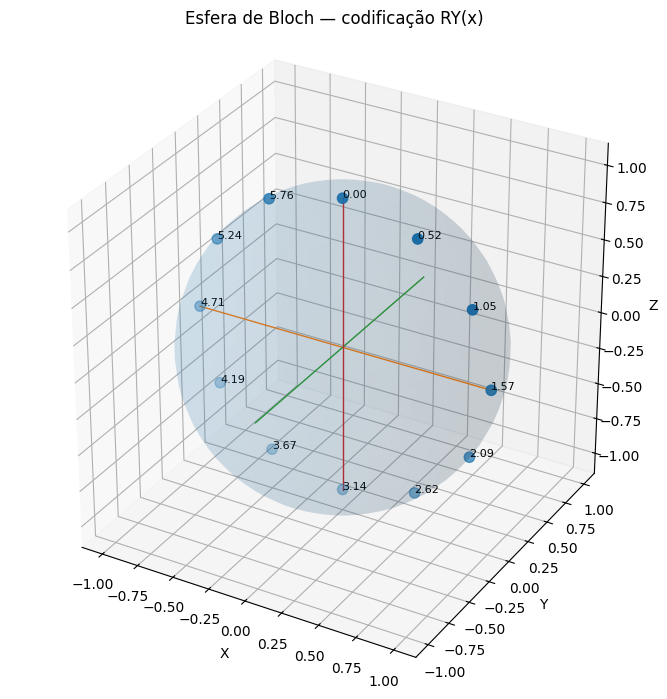

In [10]:

import numpy as np
import matplotlib.pyplot as plt

# Valores de entrada para demonstrar o mapeamento.
x_values = np.linspace(0, 2 * np.pi, 12, endpoint=False)

# Estado RY(x)|0>: vetor de Bloch.
bx = np.sin(x_values)
by = np.zeros_like(x_values)
bz = np.cos(x_values)

fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection="3d")

# Superfície da esfera.
u = np.linspace(0, 2 * np.pi, 50)
v = np.linspace(0, np.pi, 30)

sx = np.outer(np.cos(u), np.sin(v))
sy = np.outer(np.sin(u), np.sin(v))
sz = np.outer(np.ones_like(u), np.cos(v))

ax.plot_surface(
    sx, sy, sz,
    alpha=0.10,
    linewidth=0
)

# Eixos de referência.
ax.plot([-1, 1], [0, 0], [0, 0], linewidth=1)
ax.plot([0, 0], [-1, 1], [0, 0], linewidth=1)
ax.plot([0, 0], [0, 0], [-1, 1], linewidth=1)

# Pontos produzidos pela codificação.
ax.scatter(bx, by, bz, s=55)

for i, value in enumerate(x_values):
    ax.text(
        bx[i], by[i], bz[i],
        f"{value:.2f}",
        fontsize=8
    )

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.set_title("Esfera de Bloch — codificação RY(x)")
ax.set_box_aspect((1, 1, 1))
plt.tight_layout()
plt.show()


O que observar: entradas diferentes podem resultar em estados distintos.

Entretanto, valores de entrada diferentes não necessariamente produzem estados ortogonais.

Para um qubit codificado apenas com \(R_Y\), a fidelidade entre dois valores é
$
K_q(x,x')=\cos^2\left(\frac{x-x'}{2}\right).
$

Portanto, valores separados por $2\pi$ produzem o mesmo estado físico, enquanto valores separados por $\pi$ produzem estados ortogonais nessa codificação.


Em circuitos com vários qubits, rotações adicionais e emaranhamento, a geometria das similaridades pode tornar-se muito mais rica.


**Experimento 5 — Visualizar o circuito de fidelidade e o teste SWAP**

O circuito abaixo ilustra explicitamente a preparação de duas cópias dos estados e o teste SWAP. Ele serve como complemento conceitual ao cálculo de fidelidade usado anteriormente.

In [11]:

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector

# Duas entradas escalares, com um qubit para cada estado
a = ParameterVector("a", 1)
b = ParameterVector("b", 1)

# Teste SWAP: q0 = estado A, q1 = estado B, q2 = auxiliar
swap_test = QuantumCircuit(3, 1)

swap_test.ry(a[0], 0)
swap_test.ry(b[0], 1)

swap_test.h(2)
swap_test.cswap(2, 0, 1)
swap_test.h(2)

swap_test.measure(2, 0)

print(swap_test.draw(output="text"))


     ┌──────────┐           
q_0: ┤ Ry(a[0]) ├─X─────────
     ├──────────┤ │         
q_1: ┤ Ry(b[0]) ├─X─────────
     └──┬───┬───┘ │ ┌───┐┌─┐
q_2: ───┤ H ├─────■─┤ H ├┤M├
        └───┘       └───┘└╥┘
c: 1/═════════════════════╩═
                          0 


Para avaliar o circuito, associe valores numéricos a $a[0]$ e $b[0]$ e execute-o em um simulador com suporte a medições.

A partir da frequência de resultados zero no qubit auxiliar, estime a fidelidade com $K_q=2P(0)-1$.


No código da aula, a matriz de kernel é calculada por ComputeUncompute, que é uma alternativa direta para construir kernels de fidelidade com Qiskit.

O teste SWAP é mostrado para compreender outro método de estimativa, e não é necessário executá-lo para obter os resultados dos experimentos anteriores.

**Exercício 1 — Fidelidade**

Considere dois estados puros com amplitude de sobreposição $\langle\phi(x)|\phi(x')\rangle=0{,}6$. Qual é o valor do kernel quântico?

a) 0,6

b) 0,36

c) 0,64

d) 1,0

**Resolução do Exercício 1 - Fidelidade:**

A fórmula do Kernel Quântico de Fidelidade: Por definição, o kernel quântico baseado em fidelidade ($K_q$$K_q$) entre dois estados quânticos puros $|\phi(x)\rangle$$|\phi(x)\rangle$ e $|\phi(x')\rangle$$|\phi(x')\rangle$ é dado pelo módulo ao quadrado de sua amplitude de sobreposição (produto interno): $$K_q(x, x') = |\langle\phi(x)|\phi(x')\rangle|^2$$$$K_q(x, x') = |\langle\phi(x)|\phi(x')\rangle|^2$$

Substituindo o valor fornecido: O enunciado nos dá diretamente a amplitude de sobreposição: $$\langle\phi(x)|\phi(x')\rangle = 0{,}6$$$$\langle\phi(x)|\phi(x')\rangle = 0{,}6$$

Cálculo: Substituindo $0{,}6$$0{,}6$ na fórmula: $$K_q(x, x') = |0{,}6|^2 = 0{,}6 \times 0{,}6 = 0{,}36$$$$K_q(x, x') = |0{,}6|^2 = 0{,}6 \times 0{,}6 = 0{,}36$$

**Resposta correta:** **B** — 0,36. A fidelidade é o módulo quadrado da amplitude: $|0{,}6|^2=0{,}36$.

**Exercício 2 — Dimensão**


Qual é a dimensão do espaço de Hilbert de um sistema de 8 qubits?

a) 16

b) 64

c) 256

d) 512

**Resolução do Exercício 2 — Dimensão**

A dimensão do espaço de Hilbert para um sistema quântico de $n$ qubits é calculada pela fórmula exponencial $2^n$, onde a base 2 representa os dois estados possíveis de cada qubit individual ($|0\rangle$ e $|1\rangle$).

Substituindo $n = 8$:
$$\text{Dimensão} = 2^8 = 256$$

A dimensão do espaço de estados cresce exponencialmente com o número de qubits. Para apenas 8 qubits, já precisamos de 256 coeficientes complexos para descrever completamente um estado puro emaranhado geral.

**Resposta correta:** **C** — 256.

**Exercício 3 — Kernel Alignment**


Qual é a finalidade principal do QKA?

a) Maximizar o número de qubits do circuito.

b) Ajustar o kernel para torná-lo mais compatível com a estrutura dos rótulos.

c) Eliminar a necessidade de dados de treinamento.

d) Garantir acurácia de 100%

**Resolução do Exercício 3 — Kernel Alignment**

O objetivo do **QKA (Quantum Kernel Alignment)** é parametrizar o circuito de codificação de características (feature map) com parâmetros clássicos $\theta$ e otimizá-los sistematicamente.

A meta dessa otimização é maximizar a métrica de alinhamento entre a matriz de kernel resultante $K_{\theta}$ e a matriz-alvo dos rótulos $T = y y^\top$, tornando a representação geométrica do espaço de Hilbert mais compatível com a tarefa de classificação proposta.

**Resposta correta:** **B** — Ajustar o kernel para torná-lo mais compatível com a estrutura dos rótulos.

**Exercício 4 — Feature map customizado com emaranhamento**

Crie um circuito de dois qubits com duas entradas, rotações $R_Y(x_0)$ e $R_Z(x_1)$, seguido por uma CNOT.

Construa o *FidelityQuantumKernel*, calcule uma matriz de similaridade e compare-a com a matriz obtida sem CNOT.

**Resolução do Exercíco 4 - Feature map customizado com emaranhamento**

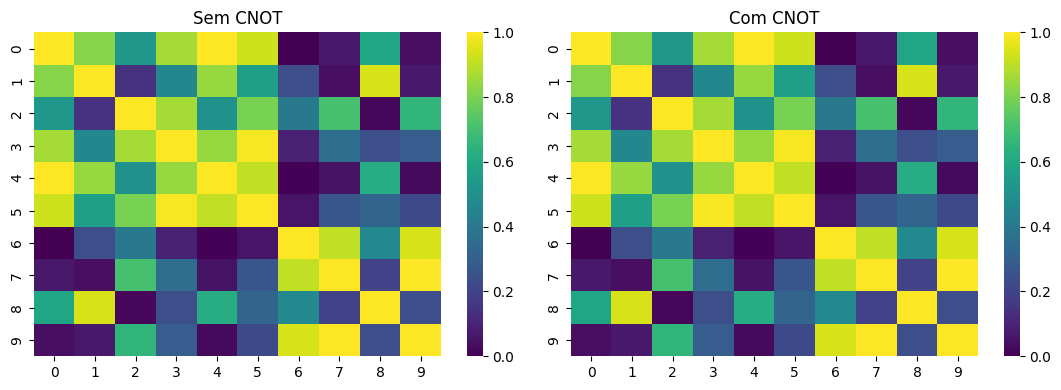

In [12]:

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit_machine_learning.kernels import FidelityQuantumKernel

x = ParameterVector("x", 2)

fm_entangled = QuantumCircuit(2)
fm_entangled.ry(x[0], 0)
fm_entangled.rz(x[1], 1)
fm_entangled.cx(0, 1)

fm_local = QuantumCircuit(2)
fm_local.ry(x[0], 0)
fm_local.rz(x[1], 1)

kernel_entangled = FidelityQuantumKernel(
    feature_map=fm_entangled,
    fidelity=fidelity
)

kernel_local = FidelityQuantumKernel(
    feature_map=fm_local,
    fidelity=fidelity
)

K_entangled = kernel_entangled.evaluate(X_train)
K_local = kernel_local.evaluate(X_train)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.heatmap(K_local, vmin=0, vmax=1, ax=axes[0], cmap="viridis")
axes[0].set_title("Sem CNOT")

sns.heatmap(K_entangled, vmin=0, vmax=1, ax=axes[1], cmap="viridis")
axes[1].set_title("Com CNOT")

plt.tight_layout()
plt.show()


**Analisando a Estrutura dos Circuitos Desenvolvidos**

Vamos comparamos as duas abordagens de codificação de dados (feature maps) para mapear os dados clássicos bidimensionais $x = (x_0, x_1)$$x = (x_0, x_1)$ em estados quânticos de 2 qubits:

Sem Emaranhamento (Mapeamento Local): Cada qubit sofre uma rotação independente controlada por uma das características de entrada. O estado gerado é um estado produto puro: $$|\phi_{\text{local}}(x)\rangle = R_Y(x_0)|0\rangle \otimes R_Z(x_1)|0\rangle$$$$|\phi_{\text{local}}(x)\rangle = R_Y(x_0)|0\rangle \otimes R_Z(x_1)|0\rangle$$

Com Emaranhamento (Mapeamento Entangled): Aplicamos as mesmas rotações locais e, em seguida, aplicamos uma porta lógica controlada-NOT (CNOT) atuando com o qubit 0 como controle e o qubit 1 como alvo. Isso permite a criação de estados emaranhados dependendo dos valores de entrada: $$|\phi_{\text{entangled}}(x)\rangle = \text{CNOT} \left( R_Y(x_0)|0\rangle \otimes R_Z(x_1)|0\rangle \right)$$$$|\phi_{\text{entangled}}(x)\rangle = \text{CNOT} \left( R_Y(x_0)|0\rangle \otimes R_Z(x_1)|0\rangle \right)$$

**Entendendo a Análise Comparativa dos Heatmaps**

A execução do código gerou duas matrizes de kernel de dimensão $10 \times 10$ e $10 \times 10$ baseadas no cálculo de fidelidade

$K_q(x, x') = |\langle\phi(x)|\phi(x')\rangle|^2$$K_q(x, x') = |\langle\phi(x)|\phi(x')\rangle|^2$:

Heatmap "**Sem CNOT**" (Esquerda):

Mostra a similaridade geométrica onde os qubits são totalmente independentes.
O comportamento da similaridade é estritamente o produto das fidelidades individuais de cada qubit:

$K_{local}(x, x') = \cos^2(\frac{x_0 - x_0'}{2})\cos^2(\frac{x_1 - x_1'}{2})$


Heatmap "**Com CNOT**" (Direita):

A introdução da porta CNOT altera as correlações geométricas entre as amostras.

Observe que alguns pares de estados que antes possuíam alta fidelidade (regiões amarelas/verdes no gráfico da esquerda) agora apresentam menor similaridade (tonalidades mais escuras no gráfico da direita), e vice-versa.


Isso ocorre porque a CNOT propaga a superposição do primeiro qubit para o segundo, gerando emaranhamento.

A sobreposição quântica entre os estados resultantes passa a depender da relação mútua e não-linear das coordenadas de entrada, enriquecendo o espaço de características quânticas (quantum feature space).


Ambas as matrizes são válidas (possuem diagonal principal igual a $1.0$$1.0$ e são estritamente simétricas), mas a inclusão da CNOT permite que o classificador explore correlações não-locais entre as variáveis clássicas de entrada.